# Data Handling & Visualization 6 — Dashboards and practical reporting

**Digital Foundation for Chemical Engineers**  \n
Duration: 60 minutes

## Today’s goal
Design a compact industrial data view that answers operational questions, reports important exceptions, and clearly states its limitations.

## 1. Dashboard concepts (10 min)

A **dashboard** is a focused visual summary for a specific audience and decision. It is not simply a screen with many charts. Before plotting, ask:

- Who will use it: operator, supervisor, engineer, or manager?
- What action should it support?
- Which few KPIs, trends, and exceptions matter?
- How current and trustworthy are the data?

For process work, show units, time period, targets/limits where appropriate, and a clear data source.

## 2. A compact shift report (15 min)

This example uses two trends and a small KPI summary. It is a reporting aid only, not a safety or control interface.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

shift = pd.read_csv('data/industrial_process_100.csv').head(24).copy()
shift['timestamp'] = pd.to_datetime(shift['timestamp'])

print('SHIFT KPI SUMMARY')
print(f"Average flow: {shift['flow_m3_h'].mean():.2f} m³/h")
print(f"Maximum temperature: {shift['temperature_c'].max():.1f} °C")
print(f"Maximum pressure: {shift['pressure_bar'].max():.2f} bar")

SHIFT KPI SUMMARY
Average flow: 12.10 m³/h
Maximum temperature: 82.9 °C
Maximum pressure: 5.20 bar


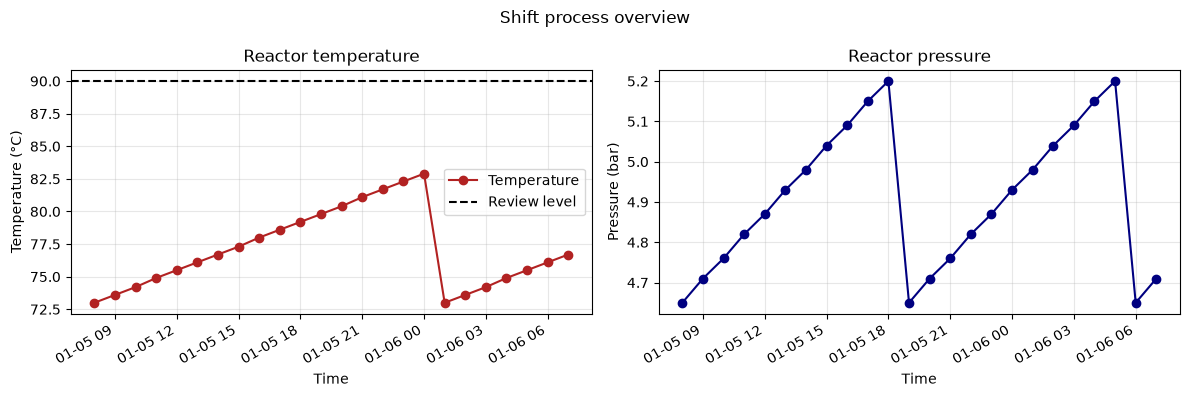

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(shift['timestamp'], shift['temperature_c'], marker='o', color='firebrick', label='Temperature')
axes[0].axhline(90, color='black', linestyle='--', label='Review level')
axes[0].set(title='Reactor temperature', xlabel='Time', ylabel='Temperature (°C)')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(shift['timestamp'], shift['pressure_bar'], marker='o', color='navy')
axes[1].set(title='Reactor pressure', xlabel='Time', ylabel='Pressure (bar)')
axes[1].grid(alpha=0.3)

fig.autofmt_xdate()
fig.suptitle('Shift process overview')
plt.tight_layout()
plt.show()

**Discuss (4 min):** Which hours require review based on the displayed temperature level? Is the chart sufficient to decide why? What additional data could help?

**Challenge:** Add a third subplot for flow rate and keep all labels readable.

## 3. Exception reporting (12 min)

A report should help a user notice exceptions without hiding the full context. Here we make a transparent rule and produce an exception table. Limits must be supplied and approved by the relevant engineering/safety process in real applications.

In [3]:
temperature_review_c = 90
pressure_review_bar = 5.3

exceptions = shift[(shift['temperature_c'] >= temperature_review_c) |
                   (shift['pressure_bar'] >= pressure_review_bar)].copy()

if exceptions.empty:
    print('No readings exceeded the review levels.')
else:
    print('Readings requiring review:')
    display(exceptions)

No readings exceeded the review levels.


## 4. Mini-project: one-page process report (15 min)

In pairs, use `shift` or create your own small DataFrame. Produce:

1. Two or three KPI values with units.
2. At least one well-labelled trend chart.
3. One explicit exception/filter rule.
4. A 2–3 sentence written shift summary: what happened, what needs review, and one limitation.

Keep it focused on a user’s decision.

**Challenge:** Save the figure with `plt.savefig('shift_report.png', dpi=150, bbox_inches='tight')` before `plt.show()`.

SHIFT KPI SUMMARY
Average flow: 12.10 m³/h
Maximum temperature: 82.9 °C
Maximum pressure: 5.20 bar

Review rule: temperature >= 90 °C or pressure >= 5.3 bar
No readings met the review rule.


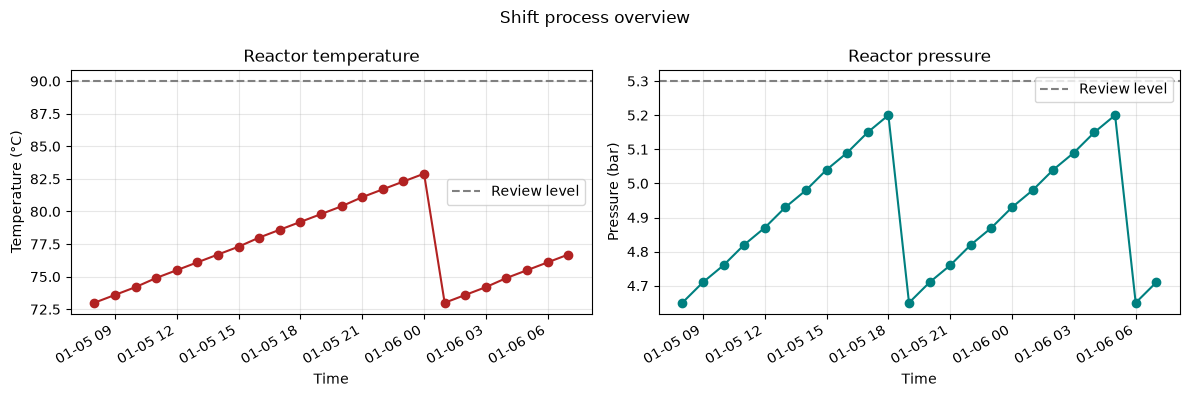


Shift summary: Across 24 readings, temperature ranged from 73.0 to 82.9 °C, and pressure ranged from 4.65 to 5.20 bar.
No readings met the stated review rule; confirm that these review levels match approved operating limits before relying on the report.
Limitation: this report covers only the first 24 readings and cannot explain the causes of any changes.


In [4]:
# Your one-page process report
import pandas as pd
import matplotlib.pyplot as plt

shift = pd.read_csv('data/industrial_process_100.csv').head(24).copy()
shift['timestamp'] = pd.to_datetime(shift['timestamp'])

# KPIs
print('SHIFT KPI SUMMARY')
print(f"Average flow: {shift['flow_m3_h'].mean():.2f} m³/h")
print(f"Maximum temperature: {shift['temperature_c'].max():.1f} °C")
print(f"Maximum pressure: {shift['pressure_bar'].max():.2f} bar")

# Explicit review rule: flag readings at or above either review level
temperature_review_c = 90
pressure_review_bar = 5.3

exceptions = shift[
    (shift['temperature_c'] >= temperature_review_c)
    | (shift['pressure_bar'] >= pressure_review_bar)
]

print(
    f"\nReview rule: temperature >= {temperature_review_c} °C "
    f"or pressure >= {pressure_review_bar} bar"
)
if exceptions.empty:
    print('No readings met the review rule.')
else:
    display(exceptions[['timestamp', 'temperature_c', 'pressure_bar']])

# Trend chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(shift['timestamp'], shift['temperature_c'], marker='o', color='firebrick')
axes[0].axhline(temperature_review_c, color='gray', linestyle='--', label='Review level')
axes[0].set(title='Reactor temperature', xlabel='Time', ylabel='Temperature (°C)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(shift['timestamp'], shift['pressure_bar'], marker='o', color='teal')
axes[1].axhline(pressure_review_bar, color='gray', linestyle='--', label='Review level')
axes[1].set(title='Reactor pressure', xlabel='Time', ylabel='Pressure (bar)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.autofmt_xdate()
fig.suptitle('Shift process overview')
fig.tight_layout()

plt.savefig('shift_report.png', dpi=150, bbox_inches='tight')
plt.show()

# Three-sentence shift summary
print(
    f"\nShift summary: Across {len(shift)} readings, temperature ranged from "
    f"{shift['temperature_c'].min():.1f} to {shift['temperature_c'].max():.1f} °C, "
    f"and pressure ranged from {shift['pressure_bar'].min():.2f} to "
    f"{shift['pressure_bar'].max():.2f} bar."
)
if exceptions.empty:
    print(
        "No readings met the stated review rule; confirm that these review levels "
        "match approved operating limits before relying on the report."
    )
else:
    print(f"{len(exceptions)} reading(s) met the review rule and should be reviewed.")
print("Limitation: this report covers only the first 24 readings and cannot explain the causes of any changes.")



## Module wrap-up

You can now move tabular data between Excel/CSV and Python; inspect, clean, sort, filter, and summarise it; and create clear charts and small reports. These are the practical foundations for later data analytics and Applied AI work in chemical industry.

Professional habit: retain raw data, document transformations, communicate uncertainty, and never treat a visualisation as proof without engineering context.